# Experiment 194 · Correlation-aware replay

**Stopped** · Stopped at the last saved window · ETA Unavailable

Local preregistration frozen 2026-11-16T11:22:27.151379+01:00. The primary comparison is correlation-aware versus fixed 25% on two time-averaged test-bank MSEs, current and historical. Both paired 95% seed-level intervals must favor correlation-aware replay to meet the primary success criterion. Secondary comparisons include inverse and random allocation. Readouts are taken every 256 arrivals, with forgetting measured at +256 and +768 from each regime switch.

After shared initial A checkpoints, every 768-arrival window contains the same images in both versions, in complementary orders. Each regime contains four clip-ordered and four shuffled windows. All arms use one optimizer update per arrival and exactly 1,536 replay updates per 6,144 arrivals.

The first 64 arrivals of every window use fixed 25%. Then correlation-aware replay compares the past prefix’s lag-1 pixel mean absolute difference to its lag-16 difference. A ratio at or below 0.70 requests 50% replay for the rest of the window, and a higher ratio requests 0%. Inverse requests the opposite. The quota allows exactly four high-rate windows per eight. Random balanced assigns four high-rate windows uniformly. Stream-order labels are used in reporting.

Completed trajectories · 5/96. Frozen downstream evaluations · 0.

## Stream and signal check

| Window order | Windows | Mean past-prefix ratio | Threshold agrees with order |
| --- | --- | --- | --- |
 | clip-ordered | 24 | 0.273 | 100.0% | 
 | shuffled | 24 | 1.009 | 100.0% | 

## Realized replay allocation

| Policy | Windows | Clip order | Shuffled | Quota-forced decisions |
| --- | --- | --- | --- | --- |
 | fixed 25% | 48 | 25.00% | 25.00% | 0.0% | 
 | correlation-aware | 24 | 47.92% | 2.08% | 25.0% | 
 | inverse | 24 | 2.08% | 47.92% | 25.0% | 
 | random balanced | 24 | 28.82% | 21.18% | 29.2% | 



In [ ]:
# Run this cell to watch the background worker. Interrupt it to stop watching.
from IPython.display import Image, Markdown, clear_output, display
from pathlib import Path
import base64, json, time

run = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-correlation-allocation')
while True:
    try:
        status = json.loads((run / 'status.json').read_text(encoding='utf-8'))
        cells = json.loads((run / 'progress.ipynb').read_text(encoding='utf-8'))['cells']
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    for cell in cells:
        if cell['cell_type'] == 'markdown':
            display(Markdown(''.join(cell['source'])))
        for output in cell.get('outputs', []):
            if png := output.get('data', {}).get('image/png'):
                display(Image(data=base64.b64decode(png)))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)


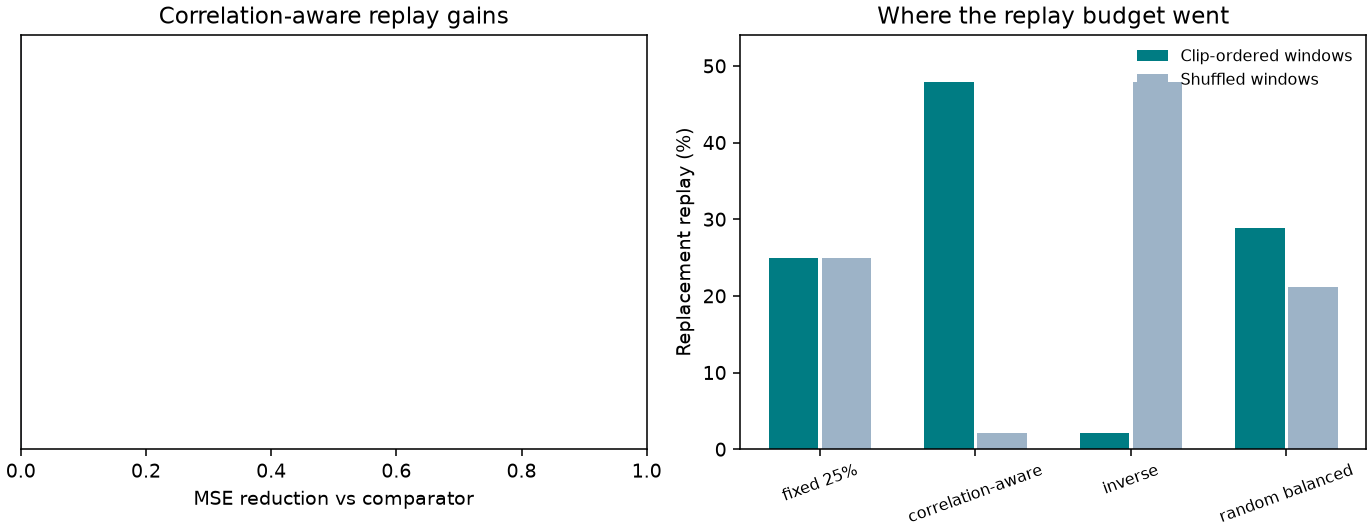